# Introduction
Visualization of the choice history bias mechanisms...

In [1]:
from riskhistory.format import rcParams
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

### DDM schematic helpers
Plot visualizations for the baseline model, pre-valuation bias, valuation bias, and drift bias. 

In [2]:
COLOR_BLACK = "#000000"
COLOR_RED   = "#E40C0C"
COLOR_BLUE  = "#0670D9"
COLOR_GAIN  = "#3ED216"
COLOR_LOSS  = "#DC1414"
TRAJ_COLOR  = "#6b6b6b"

TRAJ_ALPHA  = 0.70   # transparency for trajectories
BOUNDARY_LINEWIDTH = 2.0  # linewidth for decision boundaries
TRAJ_LINEWIDTH = 1.0  # linewidth for trajectories
DECISION_DOT_SIZE = 70  # size of decision dots
ARROW_LINEWIDTH = 1.5  # linewidth for arrows

In [3]:
def _simulate_trajectory(t, dt, z, v, sigma, a0, seed):
    """Simulate one DDM trajectory with flat boundaries until boundary hit."""
    rng = np.random.default_rng(seed)
    x = np.zeros_like(t, dtype=float)
    x[0] = z
    hit_idx, hit_y = len(t) - 1, None
    for i in range(1, len(t)):
        x[i] = x[i - 1] + v * dt + sigma * np.sqrt(dt) * rng.standard_normal()
        if x[i] >= a0:
            hit_idx, hit_y = i, a0
            break
        if x[i] <= -a0:
            hit_idx, hit_y = i, -a0
            break
    x[hit_idx] = hit_y if hit_y is not None else x[hit_idx]
    return t[:hit_idx + 1], x[:hit_idx + 1]

def _draw_boundary(ax, a0, lw=BOUNDARY_LINEWIDTH):
    ax.axhline( a0, color="black", lw=lw, zorder=2)
    ax.axhline(-a0, color="black", lw=lw, zorder=2)
    tr = ax.get_yaxis_transform()   # x in axes [0,1], y in data coords
    ax.text(0.97,  a0+0.001, "Accept Boundary", transform=tr,
            ha="right", va="bottom", color="black")
    ax.text(0.97, -a0-0.01, "Reject Boundary", transform=tr,
            ha="right", va="top", color="black")


def _draw_trajectory(ax, t, dt, z, v, sigma, a0, seed,
                     color=TRAJ_COLOR, lw=TRAJ_LINEWIDTH, 
                     alpha=TRAJ_ALPHA, s = DECISION_DOT_SIZE, label=None,
                     linestyle="solid"):
    t_traj, x_traj = _simulate_trajectory(t, dt, z, v, sigma, a0, seed)
    ax.plot(t_traj, x_traj, color=color, lw=lw, zorder=3, alpha=alpha, label=label,
           linestyle=linestyle)
    ax.scatter([t_traj[-1]], [x_traj[-1]], s=s, color=color, zorder=4, alpha=alpha)


def _draw_arrow(ax, x_start, y_start, dx, dy, color,
                lw=ARROW_LINEWIDTH, zorder=5, mutation_scale=16, linestyle="solid"):
    ann = ax.annotate(
        "", xy=(x_start + dx, y_start + dy), xytext=(x_start, y_start),
        arrowprops=dict(arrowstyle="->", lw=lw, color=color,
                        mutation_scale=mutation_scale, linestyle=linestyle),
        zorder=zorder,
    )
    return ann

def _style_ax(ax, tmax, a0, pad=0.1):
    ax.set_xlim(0, tmax)
    ax.set_ylim(-a0 - pad, a0 + pad)
    ax.spines["bottom"].set_position(("data", 0.0))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.xaxis.set_ticks_position("bottom")
    ax.xaxis.set_label_position("bottom")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Decision variable")
    ax.set_yticks([])
    ax.set_xticks(np.arange(0, tmax + 1e-9, 1.0))
    ax.tick_params(axis="x", length=7, width=2)

In [4]:
def plot_ddm_schematic(
    gain=15.0,
    loss=-5.0,
    gain2=None,
    loss2=None,
    beta_gain=0.1,
    beta_loss=0.1,
    z_choice_prev1=0.3,
    drift_bias_choice_prev1=0.25,
    beta_gain_choice_prev1=0.02,
    beta_loss_choice_prev1=0.02,
    tmax=2,
    dt=0.1,
    a0=0.5,
    sigma=1.0,
    arrow_tlen=0.3,
    arrow_scale=0.55,
    seed=10,
    diff_label=None,
    diff_label_pos=None,
    show_history=True,
    ax=None,
):
    """Single schematic combining the previous-choice effect on starting
    point, drift bias, and gain/loss value-sensitivity, all applied at once.

    Boundaries are drawn at +a0/-a0, so a0=0.5 (default) gives a total
    boundary separation of 1, matching standard DDM convention.

    If gain2/loss2 are given, a second drift arrow + trajectory per condition
    is drawn (dashed) using the same z and beta weights but this other
    gain/loss pair, and a second legend maps line style (solid/dashed) to
    the two (gain, loss) pairs.

    If show_history is False, the previous-choice split (red=accept,
    blue=reject) is collapsed to a single black condition -- used for the
    baseline (no choice-history bias) panel. In that case, the legend maps
    line style (solid/dashed) to the two (gain, loss) pairs instead of to
    previous choice.
    """
    created_fig = ax is None
    if created_fig:
        fig, ax = plt.subplots(figsize=(5, 5))
    else:
        fig = ax.figure

    t = np.arange(0, tmax + 1e-12, dt)

    if show_history:
        conditions = [
            {"choice_prev1": +1, "color": COLOR_RED},
            {"choice_prev1": -1, "color": COLOR_BLUE},
        ]
    else:
        conditions = [
            {"choice_prev1": 0, "color": COLOR_BLACK},
        ]

    has_second_gamble = gain2 is not None and loss2 is not None

    cond_params = []
    for cond in conditions:
        s = cond["choice_prev1"]
        z_c = s * z_choice_prev1
        beta_gain_c = beta_gain + s * beta_gain_choice_prev1
        beta_loss_c = beta_loss + s * beta_loss_choice_prev1
        v_c = beta_gain_c * gain + beta_loss_c * loss + s * drift_bias_choice_prev1
        entry = {**cond, "z": z_c, "v": v_c}
        if has_second_gamble:
            entry["v2"] = beta_gain_c * gain2 + beta_loss_c * loss2 + s * drift_bias_choice_prev1
        cond_params.append(entry)

    _draw_boundary(ax, a0)

    traj_labels = {COLOR_RED: "Prev. Accept", COLOR_BLUE: "Prev. Reject"}

    # Trajectories first (behind arrows)
    for cp in cond_params:
        _draw_trajectory(ax, t, dt, z=cp["z"], v=cp["v"], sigma=sigma, a0=a0, seed=seed,
                        color=cp["color"], label=traj_labels.get(cp["color"]))
        if has_second_gamble:
            _draw_trajectory(ax, t, dt, z=cp["z"], v=cp["v2"], sigma=sigma, a0=a0, seed=seed,
                            color=cp["color"], linestyle="dashed")

    # Total arrow per condition, starting from that condition's own z
    for cp in cond_params:
        _draw_arrow(ax, 0.0, cp["z"], 2 * arrow_tlen, cp["v"] * arrow_scale,
                    cp["color"], lw=6)

    # Second gain/loss pair, drawn as a dashed arrow from the same starting
    # point -- gain/loss only changes the drift (v), not the starting point (z)
    if has_second_gamble:
        for cp in cond_params:
            _draw_arrow(ax, 0.0, cp["z"], 2 * arrow_tlen, cp["v2"] * arrow_scale,
                        cp["color"], lw=6, linestyle="dashed")

    if diff_label is not None:
        x_text, y_text = diff_label_pos if diff_label_pos is not None else (1.5, 0.85 * a0)
        for i, line in enumerate(diff_label):
            ax.text(x_text, y_text, diff_label[i], ha="center", va="center")
            y_text -= 0.1 * a0


    _style_ax(ax, tmax, a0)

    if show_history:
        ax.legend(frameon=False, loc="lower left",
                  bbox_to_anchor=(0.9, -a0 - 0.05),
                  bbox_transform=ax.transData)
    elif has_second_gamble:
        style_handles = [
            Line2D([0], [0], color=COLOR_BLACK, lw=2, linestyle="solid",
                   label=f"G={gain:g}, L=-{loss:g}"),
            Line2D([0], [0], color=COLOR_BLACK, lw=2, linestyle="dashed",
                   label=f"G={gain2:g}, L=-{loss2:g}"),
        ]
        ax.legend(handles=style_handles, frameon=False, loc="lower left",
                  bbox_to_anchor=(0.9, -a0 - 0.05),
                  bbox_transform=ax.transData)

    if created_fig:
        fig.tight_layout()
    return ax


### DDM bias schematic: baseline and three mechanisms

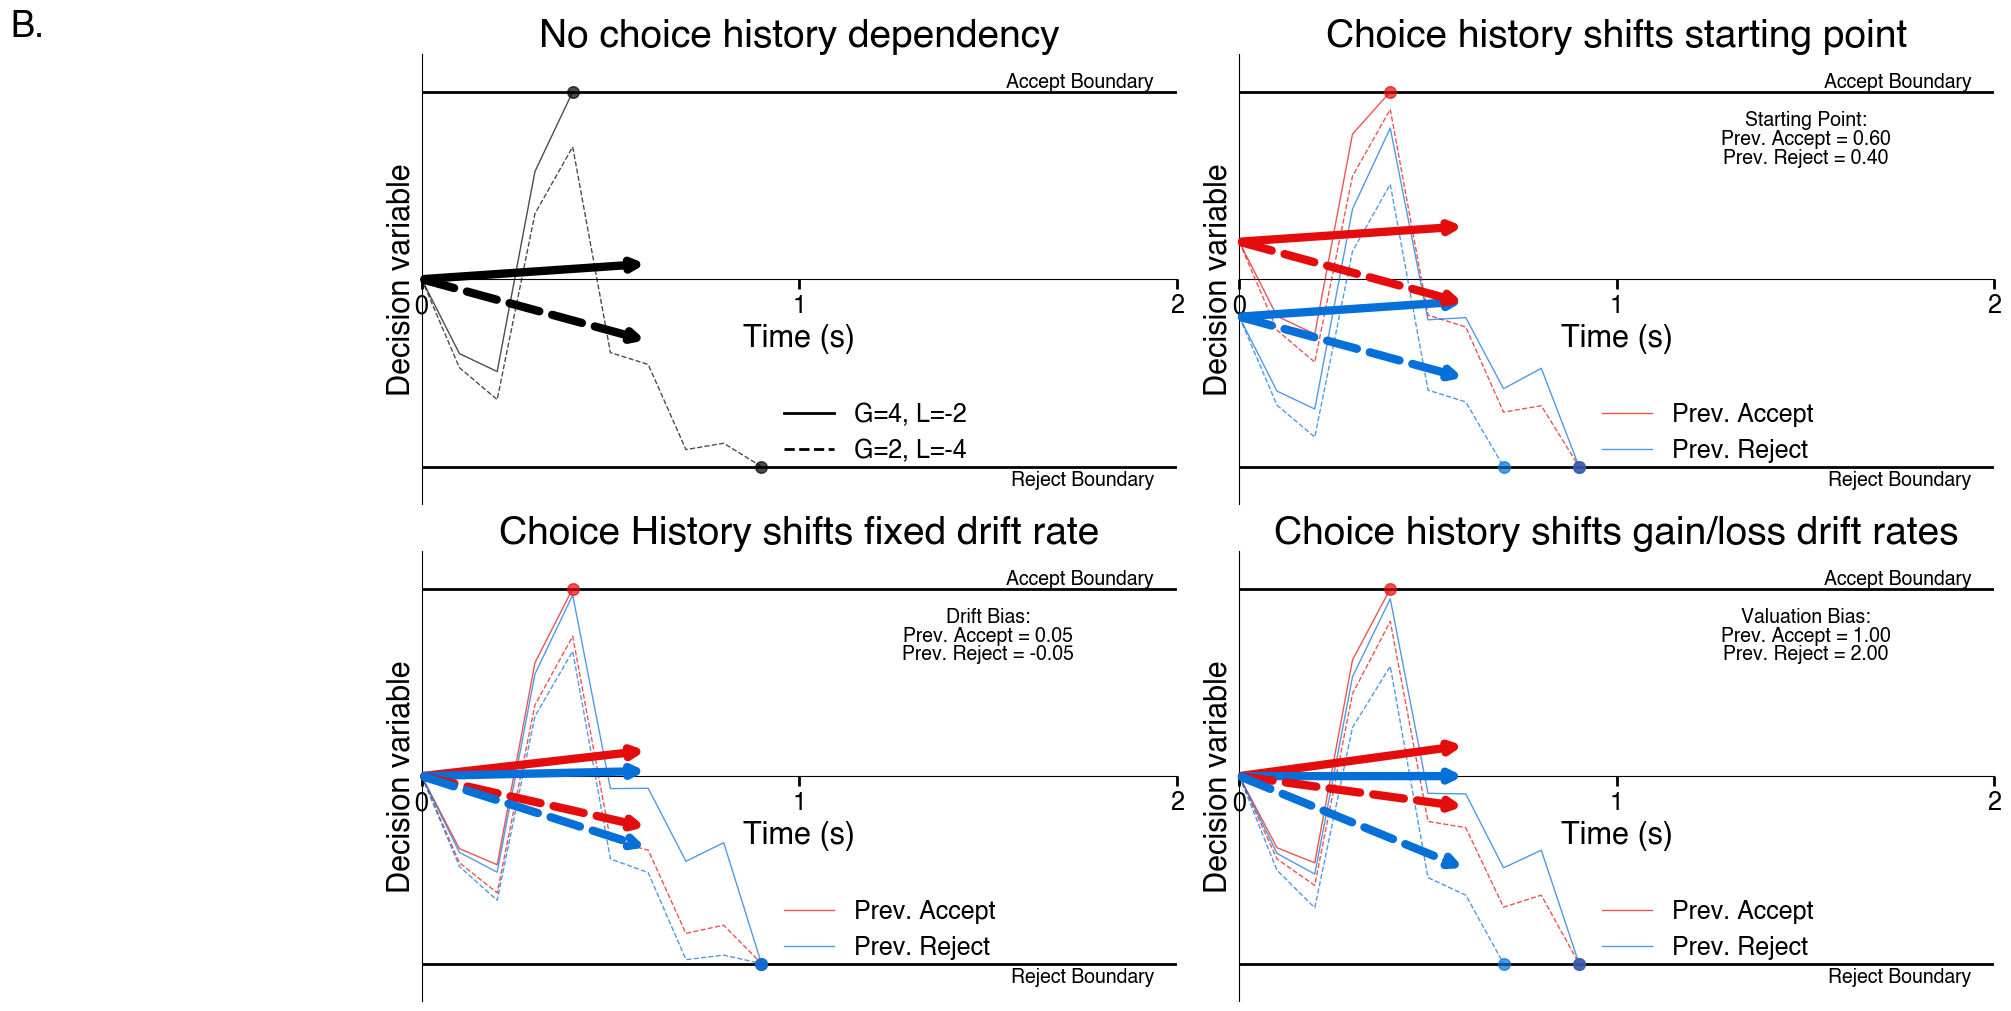

In [6]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(20, 10), layout="constrained")

A0 = 0.5  # boundary at +/-A0 -> total separation = 1

# SCALE is the ratio of the new boundary to the old boundary.
SCALE = A0 

GAIN, LOSS = 4, 2
GAIN2, LOSS2 = 2.0, 4.0  # second gamble, drawn as dashed arrows
BETA_GAIN, BETA_LOSS = 0.15 * SCALE, -0.225 * SCALE
SEED = 4

# Panel 1: Baseline -- no previous-choice bias (single black trajectory)
plot_ddm_schematic(
    gain=GAIN,
    loss=LOSS,
    gain2=GAIN2,
    loss2=LOSS2,
    beta_gain=BETA_GAIN,
    beta_loss=BETA_LOSS,
    z_choice_prev1=0.0,
    drift_bias_choice_prev1=0.0,
    beta_gain_choice_prev1=0.0,
    beta_loss_choice_prev1=0.0,
    show_history=False,
    a0=A0,
    ax=axes[0, 0],
    seed=SEED,
)
axes[0, 0].set_title("No choice history dependency")

# Panel 2: Pre-Valuation Bias -- starting point only
Z_CHOICE_PREV1 = 0.2 * SCALE
diff_z = 2 * Z_CHOICE_PREV1
plot_ddm_schematic(
    gain=GAIN,
    loss=LOSS,
    gain2=GAIN2,
    loss2=LOSS2,
    beta_gain=BETA_GAIN,
    beta_loss=BETA_LOSS,
    z_choice_prev1=Z_CHOICE_PREV1,
    drift_bias_choice_prev1=0.0,
    beta_gain_choice_prev1=0.0,
    beta_loss_choice_prev1=0.0,
    diff_label=["Starting Point:",
                f"Prev. Accept = {0.5 + Z_CHOICE_PREV1:.2f}",
                f"Prev. Reject = {0.5 + -Z_CHOICE_PREV1:.2f}"],
    a0=A0,
    ax=axes[0, 1],
    seed=SEED,
)
axes[0, 1].set_title("Choice history shifts starting point")

# Panel 3: Drift Bias only
DRIFT_BIAS_CHOICE_PREV1 = 0.1 * SCALE
diff_v = 2 * DRIFT_BIAS_CHOICE_PREV1
plot_ddm_schematic(
    gain=GAIN,
    loss=LOSS,
    gain2=GAIN2,
    loss2=LOSS2,
    beta_gain=BETA_GAIN,
    beta_loss=BETA_LOSS,
    z_choice_prev1=0.0,
    drift_bias_choice_prev1=DRIFT_BIAS_CHOICE_PREV1,
    beta_gain_choice_prev1=0.0,
    beta_loss_choice_prev1=0.0,
    diff_label=["Drift Bias:",
                f"Prev. Accept = {DRIFT_BIAS_CHOICE_PREV1:.2f}",
                f"Prev. Reject = {-DRIFT_BIAS_CHOICE_PREV1:.2f}"],
    a0=A0,
    ax=axes[1, 0],
    seed=SEED,
)
axes[1, 0].set_title("Choice History shifts fixed drift rate")

# Panel 4: Valuation Bias -- loss weight only (beta_gain_choice_prev1 = 0 here)
BETA_GAIN_CHOICE_PREV1 = 0.0
BETA_LOSS_CHOICE_PREV1 = 0.075 * SCALE
lambda_accept = abs(BETA_LOSS + BETA_LOSS_CHOICE_PREV1) / abs(BETA_GAIN + BETA_GAIN_CHOICE_PREV1)
lambda_reject = abs(BETA_LOSS - BETA_LOSS_CHOICE_PREV1) / abs(BETA_GAIN - BETA_GAIN_CHOICE_PREV1)
diff_lambda = lambda_accept - lambda_reject
plot_ddm_schematic(
    gain=GAIN,
    loss=LOSS,
    gain2=GAIN2,
    loss2=LOSS2,
    beta_gain=BETA_GAIN,
    beta_loss=BETA_LOSS,
    z_choice_prev1=0.0,
    drift_bias_choice_prev1=0.0,
    beta_gain_choice_prev1=BETA_GAIN_CHOICE_PREV1,
    beta_loss_choice_prev1=BETA_LOSS_CHOICE_PREV1,
    diff_label=["Valuation Bias:",
                f"Prev. Accept = {lambda_accept:.2f}",
                f"Prev. Reject = {lambda_reject:.2f}"],
    a0=A0,
    ax=axes[1, 1],
    seed=SEED,
)
axes[1, 1].set_title("Choice history shifts gain/loss drift rates")

# Row label, placed just outside the top-left corner of the leftmost panel
# (same convention as figure1.ipynb's "A."/"B."/"C.")
axes[0, 0].text(-0.5, 1.1, "B.", transform=axes[0, 0].transAxes,
            fontsize=26, fontweight="bold", va="top", ha="right")

fig.savefig("saved/introduction.svg", dpi=300, bbox_inches="tight")

plt.show()